In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
df = pd.read_csv("ZTF24aankvcy_20261104/forced_photometry.csv")
df.columns = df.columns.str.strip().str.lower()


In [10]:
print("total obs is", len(df))
print(df.columns)

total obs is 73
Index(['aid', 'candid', 'corrected', 'dec', 'dubious', 'e_dec', 'e_mag',
       'e_mag_corr', 'e_mag_corr_ext', 'e_ra', 'fid', 'has_stamp', 'isdiffpos',
       'mag', 'mag_corr', 'mjd', 'oid', 'parent_candid', 'pid', 'ra', 'sid',
       'tid', 'adpctdif1', 'adpctdif2', 'chinr', 'clrcoeff', 'clrcounc',
       'decnr', 'diffmaglim', 'distnr', 'exptime', 'field', 'magnr',
       'magzpsci', 'magzpscirms', 'magzpsciunc', 'procstatus', 'programid',
       'ranr', 'rcid', 'rfid', 'scibckgnd', 'sciinpseeing', 'scisigpix',
       'sharpnr', 'sigmagnr'],
      dtype='str')


In [11]:
filters = {1: ("green", "ZTF g-band"),
           2: ("red", "ZTF r-band"),
           3: ("orange", "ZTF i-band")}

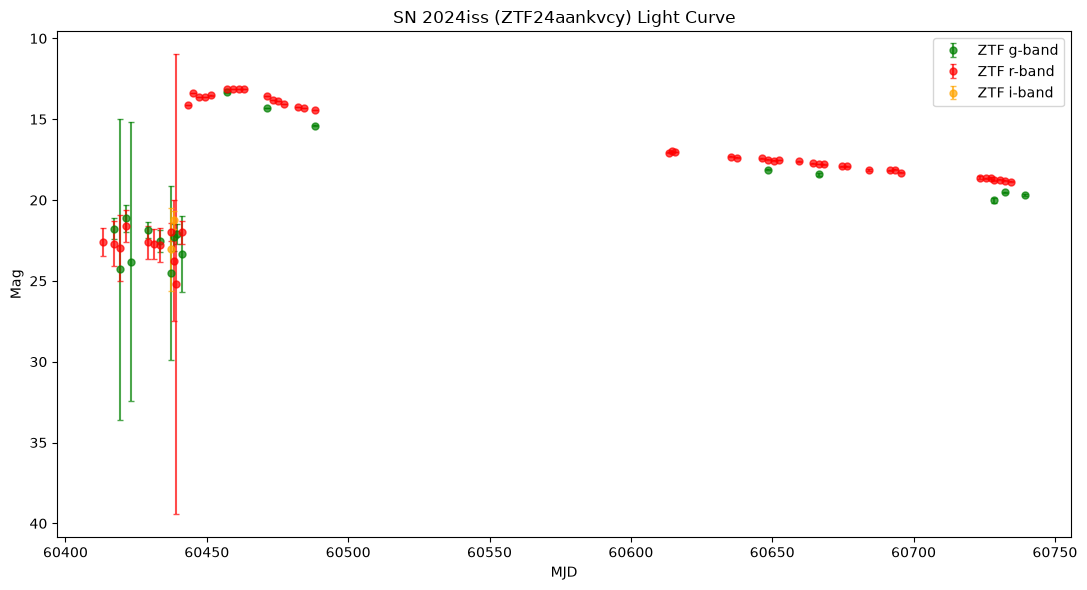

In [18]:
# Plot light curve - AlerCE 
plt.figure(figsize=(11, 6))

for fid, (color, label) in filters.items():
    filter = df[df["fid"] == fid]

    plt.errorbar(filter["mjd"], # x axis
                 filter["mag"], # y axis
                 yerr=filter["e_mag"], # error bar data
                 fmt="o",
                 markersize=5,
                 capsize=2,
                 alpha=0.7,
                 color=color,
                 label=label)

plt.gca().invert_yaxis() # low mag = brighter

plt.xlabel("MJD")
plt.ylabel("Mag")
plt.title("SN 2024iss (ZTF24aankvcy) Light Curve")
plt.legend()

plt.tight_layout()
plt.show()


In [25]:
ztf_bts = pd.read_csv("ZTF19aaknate_difference_photometry.csv")
print("total obs is", len(ztf_bts))
print(ztf_bts.columns)

total obs is 39
Index(['MJD', 'filter', 'unforced_mag', 'unforced_mag_error',
       'unforced_mag_status', 'forced_ujy', 'forced_ujy_error'],
      dtype='str')


In [30]:
ztf_bts_filters = {"g": ("green", "g-band detection"),
                   "r": ("red", "r-band detection")}

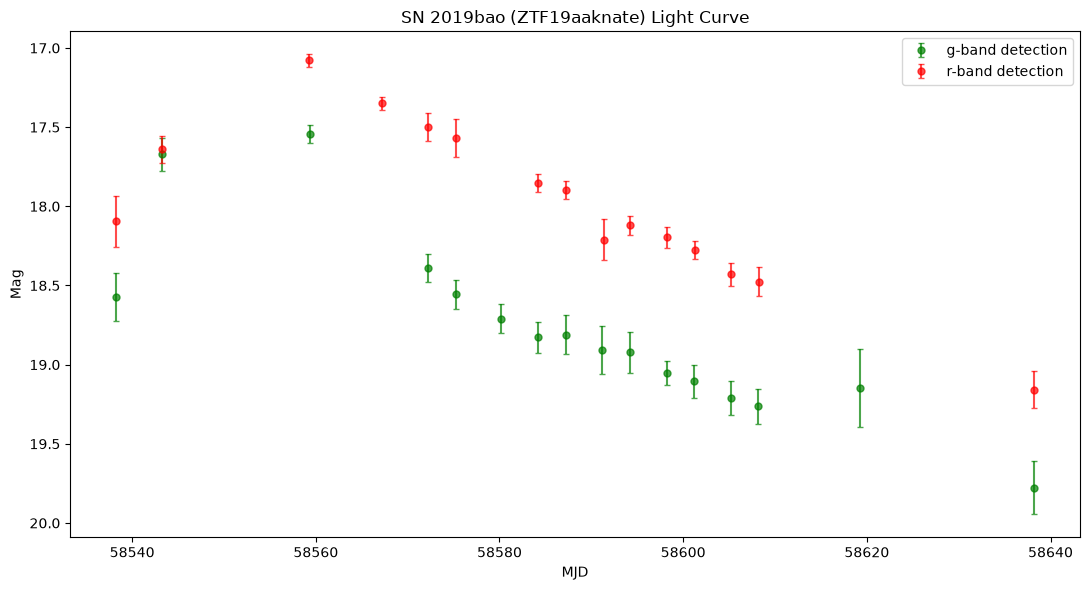

In [31]:
plt.figure(figsize=(11, 6))

for filter, (color, label) in ztf_bts_filters.items():
    filter_df = ztf_bts[(ztf_bts["filter"] == filter) &
                              (ztf_bts["unforced_mag_status"] == "positive")]

    plt.errorbar(filter_df["MJD"], # x axis
                 filter_df["unforced_mag"], # y axis
                 yerr=filter_df["unforced_mag_error"], # error bar data
                 fmt="o",
                 markersize=5,
                 capsize=2,
                 alpha=0.7,
                 color=color,
                 label=label)

plt.gca().invert_yaxis() # low mag = brighter

plt.xlabel("MJD")
plt.ylabel("Mag")
plt.title("SN 2019bao (ZTF19aaknate) Light Curve")
plt.legend()

plt.tight_layout()
plt.show()
